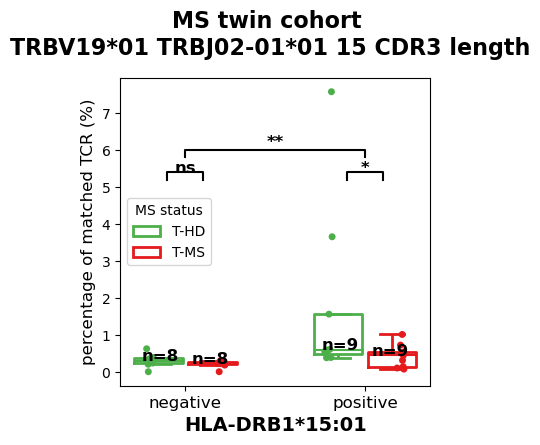

In [6]:
import pandas as pd
import numpy as np

def convert_pvalue_to_asterisks(pvalue):
    if pvalue <= 0.0001:
        return "****"
    elif pvalue <= 0.001:
        return "***"
    elif pvalue <= 0.01:
        return "**"
    elif pvalue <= 0.05:
        return "*"
    return 'ns'


import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import wilcoxon, mannwhitneyu
from bioinfokit.analys import stat


hla_df = pd.read_csv('F:/backup_E/meta_data_new_db/twins_hla_typing.tsv', sep='\t')
hla_df = hla_df[['subject_id', 'HLA_DRB1*15:01']]
hla_df.columns=['subject_id', 'HLA']
df = pd.read_csv('./twins_pct_pattern_seqs_length.tsv', sep='\t')
df['MS_status'] = df.subject_id.apply(lambda x: x.split('_')[1])
# df = df[df['percentage_vjcdr3'] < 0.07]
df.iloc[:, 1:4] = df.iloc[:, 1:4]*100
df['MS_status'] = df['MS_status'].map({'MS': 'T-MS', 'HD': 'T-HD'})

fig_df = df.merge(hla_df, on ='subject_id')
fig_df = fig_df.iloc[:,1:]

cmap=[sns.color_palette('Set1')[index] for index in [2,0]]

df1 = fig_df[fig_df['HLA'] == 0]
df2 = fig_df[fig_df['HLA'] == 1]

statis, p_hla = mannwhitneyu(df1['percentage_vj15'], df2['percentage_vj15'], alternative='less')

plt.figure(figsize=(4,4))
plt.suptitle('MS twin cohort \nTRBV19*01 TRBJ02-01*01 15 CDR3 length', fontsize=16, y=1.05, weight='bold')
fig_df1 = fig_df.copy()

fig_df1['HLA'] = fig_df1['HLA'].map({1: 'positive', 0: 'negative'})

g = sns.stripplot(x="HLA", y="percentage_vj15", data=fig_df1, dodge=True, jitter=0.05,
                  palette=cmap, hue_order=['T-HD','T-MS'], size=5, order=['negative','positive'],
                  hue='MS_status', legend=False)

sns.boxplot(data=fig_df1, x="HLA", y="percentage_vj15", fill=False, gap=.1, width=0.6, dodge=True,
            palette=cmap, hue_order=['T-HD','T-MS'], hue='MS_status', order=['negative','positive'],
            legend=True, boxprops=dict(linewidth=2), whiskerprops=dict(linewidth=2),
            capprops=dict(linewidth=2), meanprops=dict(linewidth=3), showfliers=False)

y = 6
y2 = 5.4
x_labels = [0,1]
x_ticks = [0,1]
i=0
for label, tick in zip(x_labels, x_ticks):
    min_df = fig_df[fig_df['HLA'] == label]

    df1 = min_df[min_df['MS_status'] == 'T-HD']
    df2 = min_df[min_df['MS_status'] == 'T-MS']
    num_hd = len(df1)
    num_ms = len(df2)

    statis, p_value = wilcoxon(df1['percentage_vj15'], df2['percentage_vj15'], alternative='greater')
    star = convert_pvalue_to_asterisks(p_value)
    
    g.text(i-0.14, df1['percentage_vj15'].median(), f'n={num_hd}',ha="center", size=12, fontweight='bold')
    g.text(i+0.14, df2['percentage_vj15'].median(), f'n={num_ms}',ha="center", size=12, fontweight='bold')

    plt.plot([i-0.1, i-0.1, i+0.1, i+0.1], [y2-0.2, y2, y2, y2-0.2], lw=1.5, c='black')

    g.text(i, y2, f'{star}', ha="center", fontweight='bold', size=12)
    i += 1

# for (x0, y0), (x1, y1) in zip(g.collections[0].get_offsets(), g.collections[1].get_offsets()):
#         g.plot([x0, x1], [y0, y1], color='black', ls=':', zorder=3, alpha=0.4)
# for (x0, y0), (x1, y1) in zip(g.collections[2].get_offsets(), g.collections[3].get_offsets()):
#         g.plot([x0, x1], [y0, y1], color='black', ls=':', zorder=3, alpha=0.8)
    
plt.plot([0, 0, 1, 1], [y-0.2, y, y, y-0.2], lw=1.5, color='black')
plt.text(0.5, y, f"{convert_pvalue_to_asterisks(p_hla)}", ha='center', va='bottom', fontweight='bold', size=12)

plt.xticks(fontsize=12)
plt.xlabel('HLA-DRB1*15:01', fontsize=14, fontweight='bold')
plt.ylabel('percentage of matched TCR (%)', fontsize=12)
plt.legend(title='MS status', loc='center left',)
plt.show()
plt.close()

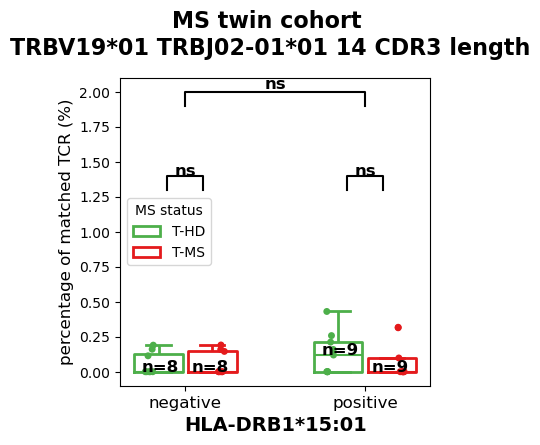

In [10]:
import pandas as pd
import numpy as np

def convert_pvalue_to_asterisks(pvalue):
    if pvalue <= 0.0001:
        return "****"
    elif pvalue <= 0.001:
        return "***"
    elif pvalue <= 0.01:
        return "**"
    elif pvalue <= 0.05:
        return "*"
    return 'ns'


import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import wilcoxon, mannwhitneyu
from bioinfokit.analys import stat


hla_df = pd.read_csv('F:/backup_E/meta_data_new_db/twins_hla_typing.tsv', sep='\t')
hla_df = hla_df[['subject_id', 'HLA_DRB1*15:01']]
hla_df.columns=['subject_id', 'HLA']
df = pd.read_csv('./twins_pct_pattern_seqs_length.tsv', sep='\t')
df['MS_status'] = df.subject_id.apply(lambda x: x.split('_')[1])
# df = df[df['percentage_vjcdr3'] < 0.07]
df.iloc[:, 1:4] = df.iloc[:, 1:4]*100
df['MS_status'] = df['MS_status'].map({'MS': 'T-MS', 'HD': 'T-HD'})

fig_df = df.merge(hla_df, on ='subject_id')
fig_df = fig_df.iloc[:,1:]

cmap=[sns.color_palette('Set1')[index] for index in [2,0]]

df1 = fig_df[fig_df['HLA'] == 0]
df2 = fig_df[fig_df['HLA'] == 1]

statis, p_hla = mannwhitneyu(df1['percentage_vj14'], df2['percentage_vj14'], alternative='less')

plt.figure(figsize=(4,4))
plt.suptitle('MS twin cohort \nTRBV19*01 TRBJ02-01*01 14 CDR3 length', fontsize=16, y=1.05, weight='bold')
fig_df1 = fig_df.copy()

fig_df1['HLA'] = fig_df1['HLA'].map({1: 'positive', 0: 'negative'})

g = sns.stripplot(x="HLA", y="percentage_vj14", data=fig_df1, dodge=True, jitter=0.05,
                  palette=cmap, hue_order=['T-HD','T-MS'], size=5, order=['negative','positive'],
                  hue='MS_status', legend=False)

sns.boxplot(data=fig_df1, x="HLA", y="percentage_vj14", fill=False, gap=.1, width=0.6, dodge=True,
            palette=cmap, hue_order=['T-HD','T-MS'], hue='MS_status', order=['negative','positive'],
            legend=True, boxprops=dict(linewidth=2), whiskerprops=dict(linewidth=2),
            capprops=dict(linewidth=2), meanprops=dict(linewidth=3), showfliers=False)

y = 2
y2 = 1.4
x_labels = [0,1]
x_ticks = [0,1]
i=0
for label, tick in zip(x_labels, x_ticks):
    min_df = fig_df[fig_df['HLA'] == label]

    df1 = min_df[min_df['MS_status'] == 'T-HD']
    df2 = min_df[min_df['MS_status'] == 'T-MS']
    num_hd = len(df1)
    num_ms = len(df2)

    statis, p_value = wilcoxon(df1['percentage_vj14'], df2['percentage_vj14'], alternative='greater')
    star = convert_pvalue_to_asterisks(p_value)
    
    g.text(i-0.14, df1['percentage_vj14'].median(), f'n={num_hd}',ha="center", size=12, fontweight='bold')
    g.text(i+0.14, df2['percentage_vj14'].median(), f'n={num_ms}',ha="center", size=12, fontweight='bold')

    plt.plot([i-0.1, i-0.1, i+0.1, i+0.1], [y2-0.1, y2, y2, y2-0.1], lw=1.5, c='black')

    g.text(i, y2, f'{star}', ha="center", fontweight='bold', size=12)
    i += 1

# for (x0, y0), (x1, y1) in zip(g.collections[0].get_offsets(), g.collections[1].get_offsets()):
#         g.plot([x0, x1], [y0, y1], color='black', ls=':', zorder=3, alpha=0.4)
# for (x0, y0), (x1, y1) in zip(g.collections[2].get_offsets(), g.collections[3].get_offsets()):
#         g.plot([x0, x1], [y0, y1], color='black', ls=':', zorder=3, alpha=0.8)
    
plt.plot([0, 0, 1, 1], [y-0.1, y, y, y-0.1], lw=1.5, color='black')
plt.text(0.5, y, f"{convert_pvalue_to_asterisks(p_hla)}", ha='center', va='bottom', fontweight='bold', size=12)

plt.xticks(fontsize=12)
plt.xlabel('HLA-DRB1*15:01', fontsize=14, fontweight='bold')
plt.ylabel('percentage of matched TCR (%)', fontsize=12)
plt.legend(title='MS status', loc='center left',)
plt.show()
plt.close()

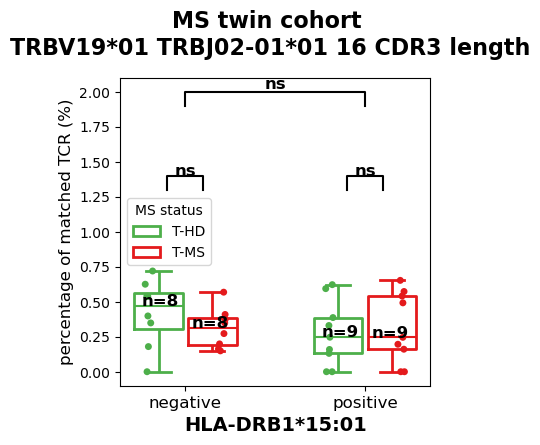

In [12]:
import pandas as pd
import numpy as np

def convert_pvalue_to_asterisks(pvalue):
    if pvalue <= 0.0001:
        return "****"
    elif pvalue <= 0.001:
        return "***"
    elif pvalue <= 0.01:
        return "**"
    elif pvalue <= 0.05:
        return "*"
    return 'ns'


import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import wilcoxon, mannwhitneyu
from bioinfokit.analys import stat


hla_df = pd.read_csv('F:/backup_E/meta_data_new_db/twins_hla_typing.tsv', sep='\t')
hla_df = hla_df[['subject_id', 'HLA_DRB1*15:01']]
hla_df.columns=['subject_id', 'HLA']
df = pd.read_csv('./twins_pct_pattern_seqs_length.tsv', sep='\t')
df['MS_status'] = df.subject_id.apply(lambda x: x.split('_')[1])
# df = df[df['percentage_vjcdr3'] < 0.07]
df.iloc[:, 1:4] = df.iloc[:, 1:4]*100
df['MS_status'] = df['MS_status'].map({'MS': 'T-MS', 'HD': 'T-HD'})

fig_df = df.merge(hla_df, on ='subject_id')
fig_df = fig_df.iloc[:,1:]

cmap=[sns.color_palette('Set1')[index] for index in [2,0]]

df1 = fig_df[fig_df['HLA'] == 0]
df2 = fig_df[fig_df['HLA'] == 1]

statis, p_hla = mannwhitneyu(df1['percentage_vj16'], df2['percentage_vj16'], alternative='less')

plt.figure(figsize=(4,4))
plt.suptitle('MS twin cohort \nTRBV19*01 TRBJ02-01*01 16 CDR3 length', fontsize=16, y=1.05, weight='bold')
fig_df1 = fig_df.copy()

fig_df1['HLA'] = fig_df1['HLA'].map({1: 'positive', 0: 'negative'})

g = sns.stripplot(x="HLA", y="percentage_vj16", data=fig_df1, dodge=True, jitter=0.05,
                  palette=cmap, hue_order=['T-HD','T-MS'], size=5, order=['negative','positive'],
                  hue='MS_status', legend=False)

sns.boxplot(data=fig_df1, x="HLA", y="percentage_vj16", fill=False, gap=.1, width=0.6, dodge=True,
            palette=cmap, hue_order=['T-HD','T-MS'], hue='MS_status', order=['negative','positive'],
            legend=True, boxprops=dict(linewidth=2), whiskerprops=dict(linewidth=2),
            capprops=dict(linewidth=2), meanprops=dict(linewidth=3), showfliers=False)

y = 2
y2 = 1.4
x_labels = [0,1]
x_ticks = [0,1]
i=0
for label, tick in zip(x_labels, x_ticks):
    min_df = fig_df[fig_df['HLA'] == label]

    df1 = min_df[min_df['MS_status'] == 'T-HD']
    df2 = min_df[min_df['MS_status'] == 'T-MS']
    num_hd = len(df1)
    num_ms = len(df2)

    statis, p_value = wilcoxon(df1['percentage_vj16'], df2['percentage_vj16'], alternative='greater')
    star = convert_pvalue_to_asterisks(p_value)
    
    g.text(i-0.14, df1['percentage_vj16'].median(), f'n={num_hd}',ha="center", size=12, fontweight='bold')
    g.text(i+0.14, df2['percentage_vj16'].median(), f'n={num_ms}',ha="center", size=12, fontweight='bold')

    plt.plot([i-0.1, i-0.1, i+0.1, i+0.1], [y2-0.1, y2, y2, y2-0.1], lw=1.5, c='black')

    g.text(i, y2, f'{star}', ha="center", fontweight='bold', size=12)
    i += 1

# for (x0, y0), (x1, y1) in zip(g.collections[0].get_offsets(), g.collections[1].get_offsets()):
#         g.plot([x0, x1], [y0, y1], color='black', ls=':', zorder=3, alpha=0.4)
# for (x0, y0), (x1, y1) in zip(g.collections[2].get_offsets(), g.collections[3].get_offsets()):
#         g.plot([x0, x1], [y0, y1], color='black', ls=':', zorder=3, alpha=0.8)
    
plt.plot([0, 0, 1, 1], [y-0.1, y, y, y-0.1], lw=1.5, color='black')
plt.text(0.5, y, f"{convert_pvalue_to_asterisks(p_hla)}", ha='center', va='bottom', fontweight='bold', size=12)

plt.xticks(fontsize=12)
plt.xlabel('HLA-DRB1*15:01', fontsize=14, fontweight='bold')
plt.ylabel('percentage of matched TCR (%)', fontsize=12)
plt.legend(title='MS status', loc='center left',)
plt.show()
plt.close()

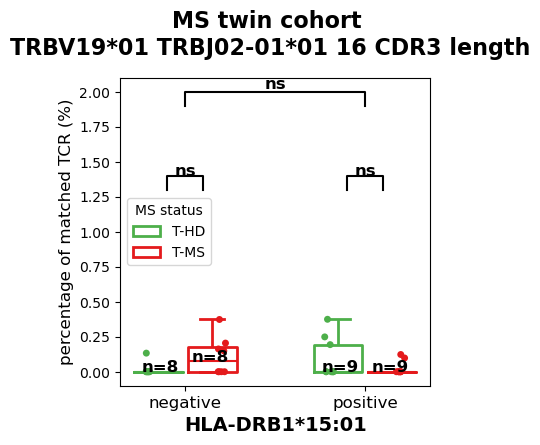

In [13]:
import pandas as pd
import numpy as np

def convert_pvalue_to_asterisks(pvalue):
    if pvalue <= 0.0001:
        return "****"
    elif pvalue <= 0.001:
        return "***"
    elif pvalue <= 0.01:
        return "**"
    elif pvalue <= 0.05:
        return "*"
    return 'ns'


import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import wilcoxon, mannwhitneyu
from bioinfokit.analys import stat


hla_df = pd.read_csv('F:/backup_E/meta_data_new_db/twins_hla_typing.tsv', sep='\t')
hla_df = hla_df[['subject_id', 'HLA_DRB1*15:01']]
hla_df.columns=['subject_id', 'HLA']
df = pd.read_csv('./twins_pct_pattern_seqs_length_drss.tsv', sep='\t')
df['MS_status'] = df.subject_id.apply(lambda x: x.split('_')[1])
# df = df[df['percentage_vjcdr3'] < 0.07]
df.iloc[:, 1:4] = df.iloc[:, 1:4]*100
df['MS_status'] = df['MS_status'].map({'MS': 'T-MS', 'HD': 'T-HD'})

fig_df = df.merge(hla_df, on ='subject_id')
fig_df = fig_df.iloc[:,1:]

cmap=[sns.color_palette('Set1')[index] for index in [2,0]]

df1 = fig_df[fig_df['HLA'] == 0]
df2 = fig_df[fig_df['HLA'] == 1]

statis, p_hla = mannwhitneyu(df1['percentage_vj16'], df2['percentage_vj16'], alternative='less')

plt.figure(figsize=(4,4))
plt.suptitle('MS twin cohort \nTRBV19*01 TRBJ02-01*01 16 CDR3 length', fontsize=16, y=1.05, weight='bold')
fig_df1 = fig_df.copy()

fig_df1['HLA'] = fig_df1['HLA'].map({1: 'positive', 0: 'negative'})

g = sns.stripplot(x="HLA", y="percentage_vj16", data=fig_df1, dodge=True, jitter=0.05,
                  palette=cmap, hue_order=['T-HD','T-MS'], size=5, order=['negative','positive'],
                  hue='MS_status', legend=False)

sns.boxplot(data=fig_df1, x="HLA", y="percentage_vj16", fill=False, gap=.1, width=0.6, dodge=True,
            palette=cmap, hue_order=['T-HD','T-MS'], hue='MS_status', order=['negative','positive'],
            legend=True, boxprops=dict(linewidth=2), whiskerprops=dict(linewidth=2),
            capprops=dict(linewidth=2), meanprops=dict(linewidth=3), showfliers=False)

y = 2
y2 = 1.4
x_labels = [0,1]
x_ticks = [0,1]
i=0
for label, tick in zip(x_labels, x_ticks):
    min_df = fig_df[fig_df['HLA'] == label]

    df1 = min_df[min_df['MS_status'] == 'T-HD']
    df2 = min_df[min_df['MS_status'] == 'T-MS']
    num_hd = len(df1)
    num_ms = len(df2)

    statis, p_value = wilcoxon(df1['percentage_vj16'], df2['percentage_vj16'], alternative='greater')
    star = convert_pvalue_to_asterisks(p_value)
    
    g.text(i-0.14, df1['percentage_vj16'].median(), f'n={num_hd}',ha="center", size=12, fontweight='bold')
    g.text(i+0.14, df2['percentage_vj16'].median(), f'n={num_ms}',ha="center", size=12, fontweight='bold')

    plt.plot([i-0.1, i-0.1, i+0.1, i+0.1], [y2-0.1, y2, y2, y2-0.1], lw=1.5, c='black')

    g.text(i, y2, f'{star}', ha="center", fontweight='bold', size=12)
    i += 1

# for (x0, y0), (x1, y1) in zip(g.collections[0].get_offsets(), g.collections[1].get_offsets()):
#         g.plot([x0, x1], [y0, y1], color='black', ls=':', zorder=3, alpha=0.4)
# for (x0, y0), (x1, y1) in zip(g.collections[2].get_offsets(), g.collections[3].get_offsets()):
#         g.plot([x0, x1], [y0, y1], color='black', ls=':', zorder=3, alpha=0.8)
    
plt.plot([0, 0, 1, 1], [y-0.1, y, y, y-0.1], lw=1.5, color='black')
plt.text(0.5, y, f"{convert_pvalue_to_asterisks(p_hla)}", ha='center', va='bottom', fontweight='bold', size=12)

plt.xticks(fontsize=12)
plt.xlabel('HLA-DRB1*15:01', fontsize=14, fontweight='bold')
plt.ylabel('percentage of matched TCR (%)', fontsize=12)
plt.legend(title='MS status', loc='center left',)
plt.show()
plt.close()

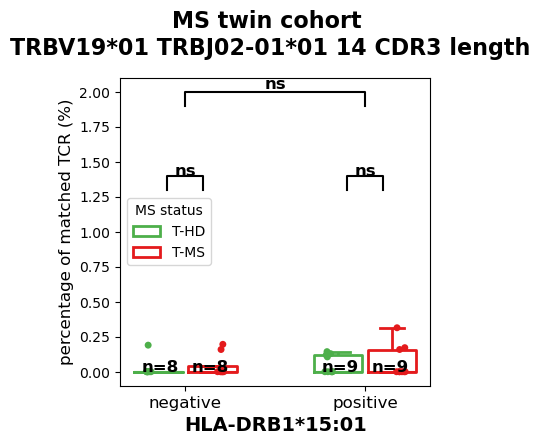

In [14]:
import pandas as pd
import numpy as np

def convert_pvalue_to_asterisks(pvalue):
    if pvalue <= 0.0001:
        return "****"
    elif pvalue <= 0.001:
        return "***"
    elif pvalue <= 0.01:
        return "**"
    elif pvalue <= 0.05:
        return "*"
    return 'ns'


import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import wilcoxon, mannwhitneyu
from bioinfokit.analys import stat


hla_df = pd.read_csv('F:/backup_E/meta_data_new_db/twins_hla_typing.tsv', sep='\t')
hla_df = hla_df[['subject_id', 'HLA_DRB1*15:01']]
hla_df.columns=['subject_id', 'HLA']
df = pd.read_csv('./twins_pct_pattern_seqs_length_drss.tsv', sep='\t')
df['MS_status'] = df.subject_id.apply(lambda x: x.split('_')[1])
# df = df[df['percentage_vjcdr3'] < 0.07]
df.iloc[:, 1:4] = df.iloc[:, 1:4]*100
df['MS_status'] = df['MS_status'].map({'MS': 'T-MS', 'HD': 'T-HD'})

fig_df = df.merge(hla_df, on ='subject_id')
fig_df = fig_df.iloc[:,1:]

cmap=[sns.color_palette('Set1')[index] for index in [2,0]]

df1 = fig_df[fig_df['HLA'] == 0]
df2 = fig_df[fig_df['HLA'] == 1]

statis, p_hla = mannwhitneyu(df1['percentage_vj14'], df2['percentage_vj14'], alternative='less')

plt.figure(figsize=(4,4))
plt.suptitle('MS twin cohort \nTRBV19*01 TRBJ02-01*01 14 CDR3 length', fontsize=16, y=1.05, weight='bold')
fig_df1 = fig_df.copy()

fig_df1['HLA'] = fig_df1['HLA'].map({1: 'positive', 0: 'negative'})

g = sns.stripplot(x="HLA", y="percentage_vj14", data=fig_df1, dodge=True, jitter=0.05,
                  palette=cmap, hue_order=['T-HD','T-MS'], size=5, order=['negative','positive'],
                  hue='MS_status', legend=False)

sns.boxplot(data=fig_df1, x="HLA", y="percentage_vj14", fill=False, gap=.1, width=0.6, dodge=True,
            palette=cmap, hue_order=['T-HD','T-MS'], hue='MS_status', order=['negative','positive'],
            legend=True, boxprops=dict(linewidth=2), whiskerprops=dict(linewidth=2),
            capprops=dict(linewidth=2), meanprops=dict(linewidth=3), showfliers=False)

y = 2
y2 = 1.4
x_labels = [0,1]
x_ticks = [0,1]
i=0
for label, tick in zip(x_labels, x_ticks):
    min_df = fig_df[fig_df['HLA'] == label]

    df1 = min_df[min_df['MS_status'] == 'T-HD']
    df2 = min_df[min_df['MS_status'] == 'T-MS']
    num_hd = len(df1)
    num_ms = len(df2)

    statis, p_value = wilcoxon(df1['percentage_vj14'], df2['percentage_vj14'], alternative='greater')
    star = convert_pvalue_to_asterisks(p_value)
    
    g.text(i-0.14, df1['percentage_vj14'].median(), f'n={num_hd}',ha="center", size=12, fontweight='bold')
    g.text(i+0.14, df2['percentage_vj14'].median(), f'n={num_ms}',ha="center", size=12, fontweight='bold')

    plt.plot([i-0.1, i-0.1, i+0.1, i+0.1], [y2-0.1, y2, y2, y2-0.1], lw=1.5, c='black')

    g.text(i, y2, f'{star}', ha="center", fontweight='bold', size=12)
    i += 1

# for (x0, y0), (x1, y1) in zip(g.collections[0].get_offsets(), g.collections[1].get_offsets()):
#         g.plot([x0, x1], [y0, y1], color='black', ls=':', zorder=3, alpha=0.4)
# for (x0, y0), (x1, y1) in zip(g.collections[2].get_offsets(), g.collections[3].get_offsets()):
#         g.plot([x0, x1], [y0, y1], color='black', ls=':', zorder=3, alpha=0.8)
    
plt.plot([0, 0, 1, 1], [y-0.1, y, y, y-0.1], lw=1.5, color='black')
plt.text(0.5, y, f"{convert_pvalue_to_asterisks(p_hla)}", ha='center', va='bottom', fontweight='bold', size=12)

plt.xticks(fontsize=12)
plt.xlabel('HLA-DRB1*15:01', fontsize=14, fontweight='bold')
plt.ylabel('percentage of matched TCR (%)', fontsize=12)
plt.legend(title='MS status', loc='center left',)
plt.show()
plt.close()

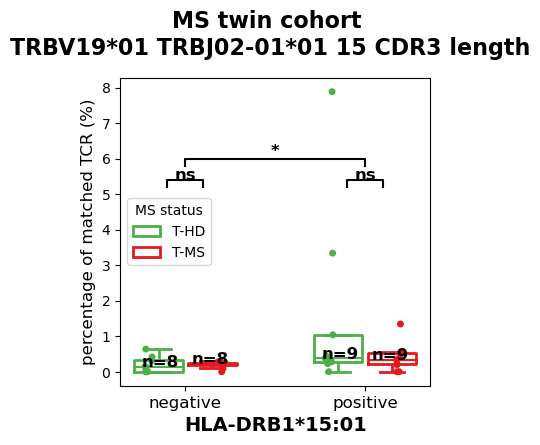

In [15]:
import pandas as pd
import numpy as np

def convert_pvalue_to_asterisks(pvalue):
    if pvalue <= 0.0001:
        return "****"
    elif pvalue <= 0.001:
        return "***"
    elif pvalue <= 0.01:
        return "**"
    elif pvalue <= 0.05:
        return "*"
    return 'ns'


import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import wilcoxon, mannwhitneyu
from bioinfokit.analys import stat


hla_df = pd.read_csv('F:/backup_E/meta_data_new_db/twins_hla_typing.tsv', sep='\t')
hla_df = hla_df[['subject_id', 'HLA_DRB1*15:01']]
hla_df.columns=['subject_id', 'HLA']
df = pd.read_csv('./twins_pct_pattern_seqs_length_drss.tsv', sep='\t')
df['MS_status'] = df.subject_id.apply(lambda x: x.split('_')[1])
# df = df[df['percentage_vjcdr3'] < 0.07]
df.iloc[:, 1:4] = df.iloc[:, 1:4]*100
df['MS_status'] = df['MS_status'].map({'MS': 'T-MS', 'HD': 'T-HD'})

fig_df = df.merge(hla_df, on ='subject_id')
fig_df = fig_df.iloc[:,1:]

cmap=[sns.color_palette('Set1')[index] for index in [2,0]]

df1 = fig_df[fig_df['HLA'] == 0]
df2 = fig_df[fig_df['HLA'] == 1]

statis, p_hla = mannwhitneyu(df1['percentage_vj15'], df2['percentage_vj15'], alternative='less')

plt.figure(figsize=(4,4))
plt.suptitle('MS twin cohort \nTRBV19*01 TRBJ02-01*01 15 CDR3 length', fontsize=16, y=1.05, weight='bold')
fig_df1 = fig_df.copy()

fig_df1['HLA'] = fig_df1['HLA'].map({1: 'positive', 0: 'negative'})

g = sns.stripplot(x="HLA", y="percentage_vj15", data=fig_df1, dodge=True, jitter=0.05,
                  palette=cmap, hue_order=['T-HD','T-MS'], size=5, order=['negative','positive'],
                  hue='MS_status', legend=False)

sns.boxplot(data=fig_df1, x="HLA", y="percentage_vj15", fill=False, gap=.1, width=0.6, dodge=True,
            palette=cmap, hue_order=['T-HD','T-MS'], hue='MS_status', order=['negative','positive'],
            legend=True, boxprops=dict(linewidth=2), whiskerprops=dict(linewidth=2),
            capprops=dict(linewidth=2), meanprops=dict(linewidth=3), showfliers=False)

y = 6
y2 = 5.4
x_labels = [0,1]
x_ticks = [0,1]
i=0
for label, tick in zip(x_labels, x_ticks):
    min_df = fig_df[fig_df['HLA'] == label]

    df1 = min_df[min_df['MS_status'] == 'T-HD']
    df2 = min_df[min_df['MS_status'] == 'T-MS']
    num_hd = len(df1)
    num_ms = len(df2)

    statis, p_value = wilcoxon(df1['percentage_vj15'], df2['percentage_vj15'], alternative='greater')
    star = convert_pvalue_to_asterisks(p_value)
    
    g.text(i-0.14, df1['percentage_vj15'].median(), f'n={num_hd}',ha="center", size=12, fontweight='bold')
    g.text(i+0.14, df2['percentage_vj15'].median(), f'n={num_ms}',ha="center", size=12, fontweight='bold')

    plt.plot([i-0.1, i-0.1, i+0.1, i+0.1], [y2-0.2, y2, y2, y2-0.2], lw=1.5, c='black')

    g.text(i, y2, f'{star}', ha="center", fontweight='bold', size=12)
    i += 1

# for (x0, y0), (x1, y1) in zip(g.collections[0].get_offsets(), g.collections[1].get_offsets()):
#         g.plot([x0, x1], [y0, y1], color='black', ls=':', zorder=3, alpha=0.4)
# for (x0, y0), (x1, y1) in zip(g.collections[2].get_offsets(), g.collections[3].get_offsets()):
#         g.plot([x0, x1], [y0, y1], color='black', ls=':', zorder=3, alpha=0.8)
    
plt.plot([0, 0, 1, 1], [y-0.2, y, y, y-0.2], lw=1.5, color='black')
plt.text(0.5, y, f"{convert_pvalue_to_asterisks(p_hla)}", ha='center', va='bottom', fontweight='bold', size=12)

plt.xticks(fontsize=12)
plt.xlabel('HLA-DRB1*15:01', fontsize=14, fontweight='bold')
plt.ylabel('percentage of matched TCR (%)', fontsize=12)
plt.legend(title='MS status', loc='center left',)
plt.show()
plt.close()

('ms01', 'hips') 0.9489459974442208
('ms03', 'hips') 0.3902815910716806


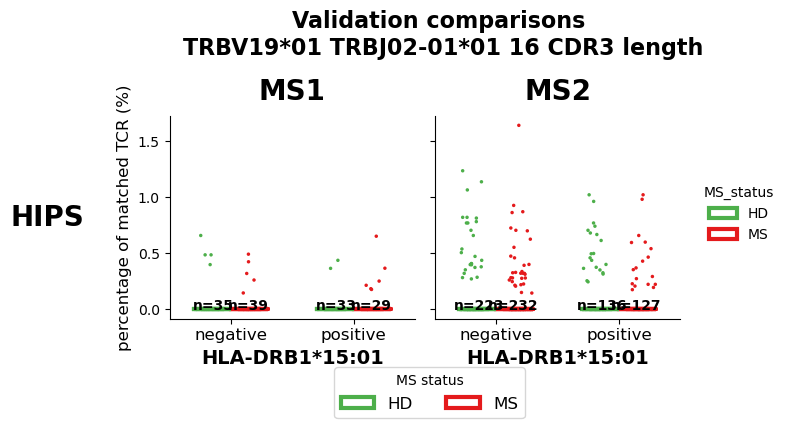

In [46]:
def convert_pvalue_to_asterisks(pvalue):
    if pvalue <= 0.0001:
        return "****"
    elif pvalue <= 0.001:
        return "***"
    elif pvalue <= 0.01:
        return "**"
    elif pvalue <= 0.05:
        return "*"
    return 'ns'

def myfunc(string):
    if 'MS' in string:
        x = 'MS'
    else: x = 'HD'
    return x
    

def annotate(data, **kws):
    
    x = data.groupby(['MS_datasets', 'HD_datasets']).size().index[0]
    p_pos = rslt_df.loc[f'{x}']['p_pos']
    p_hla = rslt_df.loc[f'{x}']['p_hla']
    
    star1 = convert_pvalue_to_asterisks(p_pos)
    star3 = convert_pvalue_to_asterisks(p_hla)

    x1, x2 = 0, 1   # columns 'Sat' and 'Sun' (first column: 0, see plt.xticks())
    x3, x4 = -0.1, 0.1
    x5, x6 = 0.9, 1.1
    y1 = final_df['percentage_vj16'].max()
    y2 = final_df['percentage_vj16'].max() #- final_df['percentage_vj16'].max() /0.04
    h = final_df['percentage_vj16'].max()/50
    col = 'black'

    if star3 != 'ns':
        plt.plot([x1, x1, x2, x2], [y1, y1+h, y1+h, y1], lw=1.5, c=col)
        plt.text((x1+x2)*.5, y1, f"{star3}", ha='center', va='bottom', color=col, fontsize=15, fontweight='bold') # {round(p_hla,3)} 
    if star1 != 'ns':
        plt.plot([x5, x5, x6, x6], [y2, y2+h, y2+h, y2], lw=1.5, c=col)
        plt.text((x5+x6)*.5, y2, f"{star1}", ha='center', va='bottom', color=col, fontsize=15, fontweight='bold') # {round(p_pos, 3)} 
    # if star2 != 'ns':
    #     plt.plot([x3, x3, x4, x4], [y2, y2+h, y2+h, y2], lw=1.5, c=col)
    #     plt.text((x3+x4)*.5, y2, f"{star2}", ha='center', va='bottom', color=col, fontsize=15, fontweight='bold') # {round(p_neg, 3)} 
    
    x_labels = ['negative', 'positive']
    x_ticks = [0, 1]
    i=0
    # Print x-tick positions and corresponding labels
    for label, tick in zip(x_labels, x_ticks):
        min_df = data[data['HLA'] == label]

        df1 = min_df[min_df['MS_status'] == 'HD']
        df2 = min_df[min_df['MS_status'] == 'MS']
    
        plt.text(i-0.14, df1['percentage_vj16'].median(), f'n={len(df1)}',ha="center", size=10, fontweight='bold')
        plt.text(i+0.14, df2['percentage_vj16'].median(), f'n={len(df2)}',ha="center", size=10, fontweight='bold')

        i += 1
    plt.xlabel('HLA-DRB1*15:01', fontsize=14, fontweight='bold')
    plt.ylabel('percentage of matched TCR (%)', fontsize=12)

    
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from scipy.stats import wilcoxon, mannwhitneyu
from bioinfokit.analys import stat

ms_datasets = ['ms01', 'ms03']
hd_datasets = ['hips']

final_df = pd.DataFrame()
for ms_dataset in ms_datasets:
    for hd_dataset in hd_datasets:
        subject_df = pd.read_csv(f'./subject_list/{ms_dataset}_hips.tsv', sep='\t')
        subject_list = subject_df.subject_id.values.tolist()

        hla_df1 = pd.read_csv(f'F:/backup_E/meta_data_new_db/{ms_dataset}_hla_typing.tsv', sep='\t')
        hla_df1 = hla_df1[['subject_id', 'HLA_DRB1*15:01']]

        hla_df2 = pd.read_csv(f'F:/backup_E/meta_data_new_db/hips_hla_typing.tsv', sep='\t')
        hla_df2 = hla_df2[['subject_id', 'HLA_DRB1*15:01']]

        hla_df = pd.concat([hla_df1, hla_df2], ignore_index=True, sort=False)
        hla_df.columns=['subject_id', 'HLA']
        
        ms_df = pd.read_csv(f'./comparison_hips/{ms_dataset}_pct_pattern_seqs_length_drss.tsv', sep='\t')
        hd_df = pd.read_csv(f'./comparison_hips/hips_pct_pattern_seqs_length_drss.tsv', sep='\t')
        df = pd.concat([ms_df, hd_df], ignore_index=True, sort=False)
        df['MS_status'] = df.subject_id.apply(lambda x: myfunc(x))
        df = df[df['subject_id'].isin(subject_list)]
        fig_df = df[df['percentage_vj16'] < 0.07]
        fig_df = fig_df.merge(hla_df, on ='subject_id')

        fig_df.insert(0, 'HD_datasets', hd_dataset)
        fig_df.insert(1, 'MS_datasets', ms_dataset)
        final_df = pd.concat([final_df, fig_df], ignore_index=True, sort=False)
        
final_df['MS_status'] = final_df['MS_status'].map({'MS': 1, 'HD': 0})
final_df['percentage_vj16'] = final_df['percentage_vj16']*100
# fig_df = final_df[final_df['percentage_vj16'] < 0.07]
cmap=[sns.color_palette('Set1')[index] for index in [2,0]]

rslt_df = pd.DataFrame()
for dataset, sub_df1 in final_df.groupby(['MS_datasets', 'HD_datasets']):
    sub_df = sub_df1[['percentage_vj16', 'MS_status', 'HLA']]
    # sub_df = sub_df[sub_df['percentage_vj'] > 0]

    hla_pos = sub_df[sub_df['HLA'] == 1]
    hla_neg = sub_df[sub_df['HLA'] == 0]
    stats_hla, p_hla = mannwhitneyu(hla_pos['percentage_vj16'], hla_neg['percentage_vj16'], alternative='greater')

    ms = hla_pos[hla_pos['MS_status'] == 1]
    hd = hla_pos[hla_pos['MS_status'] == 0]
    stats_pos, p_pos = mannwhitneyu(hd['percentage_vj16'], ms['percentage_vj16'], alternative='greater')
    print(dataset, p_pos)
    
    model = ({
        'datasets': [f'{dataset}'],
        'p_pos': [p_pos],
        'p_hla': [p_hla]
    })

    model_df = pd.DataFrame(model)
    rslt_df = pd.concat([rslt_df, model_df], ignore_index=True, sort=False)

rslt_df['datasets'] = rslt_df['datasets'].str.replace('0', '')
rslt_df['datasets'] = rslt_df['datasets'].str.replace('0', '')
rslt_df['datasets'] = rslt_df['datasets'].str.replace('microhd', 'hd3')
rslt_df = rslt_df.set_index('datasets')

final_df["MS_status"] = final_df["MS_status"].map({0: "HD", 1: "MS"})
final_df['HLA'] = final_df['HLA'].map({0: 'negative', 1: 'positive'})
final_df['MS_datasets'] = final_df['MS_datasets'].str.replace('0', '')
final_df['HD_datasets'] = final_df['HD_datasets'].str.replace('0', '')
final_df['HD_datasets'] = final_df['HD_datasets'].str.replace('microhd', 'hd3')

hue_order = ['HD', 'MS']
g = sns.catplot(x="HLA", y="percentage_vj16", hue="MS_status", hue_order=hue_order,
                col='MS_datasets', row='HD_datasets', order=['negative', 'positive'], palette=cmap, legend=True,height=3, aspect=1,
                data=final_df, kind='box', showfliers = False, fill=False, boxprops=dict(linewidth=3), whiskerprops=dict(linewidth=3),
            capprops=dict(linewidth=3), medianprops=dict(linewidth=3), width=0.6)
g.map(sns.stripplot, "HLA", "percentage_vj16", 'MS_status', palette=cmap,
      hue_order=hue_order, jitter=0.2, order=['negative', 'positive'],
      size=2.5, dodge=True, legend=False)
g.map_dataframe(annotate)
# g.set_titles(('{row_name}' ' vs. ' '{col_name}'), size=18, weight='bold')
g.set_titles("")
g.figure.suptitle(
    'Validation comparisons \nTRBV19*01 TRBJ02-01*01 16 CDR3 length',
    fontsize=16,
    fontweight="bold",
    y=1.24
)

for ax, row_name in zip(g.axes[:, 0], g.row_names):
    ax.annotate(row_name.upper(), xy=(-0.5, 0.5), xycoords=ax.transAxes, 
                va='center', ha='center', fontsize=20, weight='bold')

for ax, col_name in zip(g.axes[0], g.col_names):
    if col_name == 'ms3':
        col_name = 'ms2'
    else: col_name = col_name
    ax.set_title(col_name.upper(), fontsize=20, weight='bold', y=1.04)

for ax in g.axes.flat:
    ax.tick_params(axis='x',  labelsize=12)

# g.legend.set_bbox_to_anchor((1.15, 0.5))

plt.legend(bbox_to_anchor=(0.4, -0.2), fontsize=12, ncol=2, title='MS status')

# plt.setp(g.legend.texts, fontsize='16')
# plt.setp(g.legend.get_title(), fontsize='16')

# figre_name = os.path.join('E:/Document/2024/06_18_review_untreated_samples/validation/boxplots/', f'{hla_name}.png')
# plt.savefig(figre_name, bbox_inches='tight')
plt.show()
plt.close()

('ms01', 'hips') 0.6064050946722759
('ms03', 'hips') 0.6966835142755744


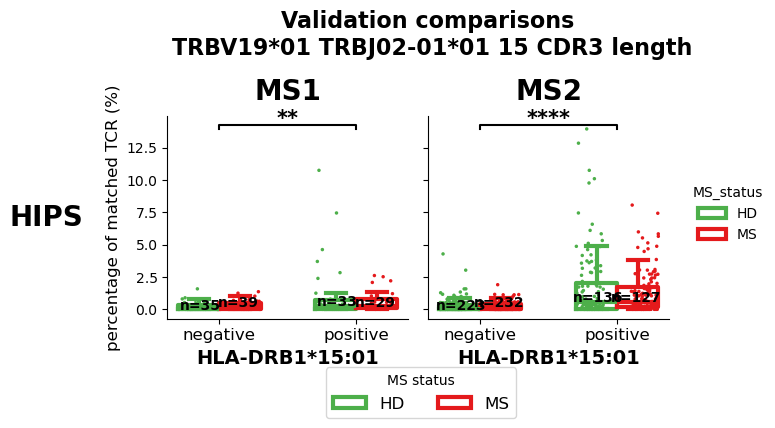

In [47]:
def convert_pvalue_to_asterisks(pvalue):
    if pvalue <= 0.0001:
        return "****"
    elif pvalue <= 0.001:
        return "***"
    elif pvalue <= 0.01:
        return "**"
    elif pvalue <= 0.05:
        return "*"
    return 'ns'

def myfunc(string):
    if 'MS' in string:
        x = 'MS'
    else: x = 'HD'
    return x
    

def annotate(data, **kws):
    
    x = data.groupby(['MS_datasets', 'HD_datasets']).size().index[0]
    p_pos = rslt_df.loc[f'{x}']['p_pos']
    p_hla = rslt_df.loc[f'{x}']['p_hla']
    
    star1 = convert_pvalue_to_asterisks(p_pos)
    star3 = convert_pvalue_to_asterisks(p_hla)

    x1, x2 = 0, 1   # columns 'Sat' and 'Sun' (first column: 0, see plt.xticks())
    x3, x4 = -0.1, 0.1
    x5, x6 = 0.9, 1.1
    y1 = final_df['percentage_vj15'].max()
    y2 = final_df['percentage_vj15'].max() - final_df['percentage_vj15'].max() /0.04
    h = final_df['percentage_vj15'].max()/50
    col = 'black'

    if star3 != 'ns':
        plt.plot([x1, x1, x2, x2], [y1, y1+h, y1+h, y1], lw=1.5, c=col)
        plt.text((x1+x2)*.5, y1, f"{star3}", ha='center', va='bottom', color=col, fontsize=15, fontweight='bold') # {round(p_hla,3)} 
    if star1 != 'ns':
        plt.plot([x5, x5, x6, x6], [y2, y2+h, y2+h, y2], lw=1.5, c=col)
        plt.text((x5+x6)*.5, y2, f"{star1}", ha='center', va='bottom', color=col, fontsize=15, fontweight='bold') # {round(p_pos, 3)} 
    # if star2 != 'ns':
    #     plt.plot([x3, x3, x4, x4], [y2, y2+h, y2+h, y2], lw=1.5, c=col)
    #     plt.text((x3+x4)*.5, y2, f"{star2}", ha='center', va='bottom', color=col, fontsize=15, fontweight='bold') # {round(p_neg, 3)} 
    
    x_labels = ['negative', 'positive']
    x_ticks = [0, 1]
    i=0
    # Print x-tick positions and corresponding labels
    for label, tick in zip(x_labels, x_ticks):
        min_df = data[data['HLA'] == label]

        df1 = min_df[min_df['MS_status'] == 'HD']
        df2 = min_df[min_df['MS_status'] == 'MS']
    
        plt.text(i-0.14, df1['percentage_vj15'].median(), f'n={len(df1)}',ha="center", size=10, fontweight='bold')
        plt.text(i+0.14, df2['percentage_vj15'].median(), f'n={len(df2)}',ha="center", size=10, fontweight='bold')

        i += 1
    plt.xlabel('HLA-DRB1*15:01', fontsize=14, fontweight='bold')
    plt.ylabel('percentage of matched TCR (%)', fontsize=12)

    
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from scipy.stats import wilcoxon, mannwhitneyu
from bioinfokit.analys import stat

ms_datasets = ['ms01', 'ms03']
hd_datasets = ['hips']

final_df = pd.DataFrame()
for ms_dataset in ms_datasets:
    for hd_dataset in hd_datasets:
        subject_df = pd.read_csv(f'./subject_list/{ms_dataset}_hips.tsv', sep='\t')
        subject_list = subject_df.subject_id.values.tolist()

        hla_df1 = pd.read_csv(f'F:/backup_E/meta_data_new_db/{ms_dataset}_hla_typing.tsv', sep='\t')
        hla_df1 = hla_df1[['subject_id', 'HLA_DRB1*15:01']]

        hla_df2 = pd.read_csv(f'F:/backup_E/meta_data_new_db/hips_hla_typing.tsv', sep='\t')
        hla_df2 = hla_df2[['subject_id', 'HLA_DRB1*15:01']]

        hla_df = pd.concat([hla_df1, hla_df2], ignore_index=True, sort=False)
        hla_df.columns=['subject_id', 'HLA']
        
        ms_df = pd.read_csv(f'./comparison_hips/{ms_dataset}_pct_pattern_seqs_length_drss.tsv', sep='\t')
        hd_df = pd.read_csv(f'./comparison_hips/hips_pct_pattern_seqs_length_drss.tsv', sep='\t')
        df = pd.concat([ms_df, hd_df], ignore_index=True, sort=False)
        df['MS_status'] = df.subject_id.apply(lambda x: myfunc(x))
        df = df[df['subject_id'].isin(subject_list)]
        fig_df = df.copy() #df[df['percentage_vj15'] != 0]
        fig_df = fig_df.merge(hla_df, on ='subject_id')

        fig_df.insert(0, 'HD_datasets', hd_dataset)
        fig_df.insert(1, 'MS_datasets', ms_dataset)
        final_df = pd.concat([final_df, fig_df], ignore_index=True, sort=False)
        
final_df['MS_status'] = final_df['MS_status'].map({'MS': 1, 'HD': 0})
final_df['percentage_vj15'] = final_df['percentage_vj15']*100
# fig_df = final_df[final_df['percentage_vj16'] < 0.07]
cmap=[sns.color_palette('Set1')[index] for index in [2,0]]

rslt_df = pd.DataFrame()
for dataset, sub_df1 in final_df.groupby(['MS_datasets', 'HD_datasets']):
    sub_df = sub_df1[['percentage_vj15', 'MS_status', 'HLA']]
    # sub_df = sub_df[sub_df['percentage_vj'] > 0]

    hla_pos = sub_df[sub_df['HLA'] == 1]
    hla_neg = sub_df[sub_df['HLA'] == 0]
    stats_hla, p_hla = mannwhitneyu(hla_pos['percentage_vj15'], hla_neg['percentage_vj15'], alternative='greater')

    ms = hla_pos[hla_pos['MS_status'] == 1]
    hd = hla_pos[hla_pos['MS_status'] == 0]
    stats_pos, p_pos = mannwhitneyu(hd['percentage_vj15'], ms['percentage_vj15'], alternative='greater')
    print(dataset, p_pos)
    
    model = ({
        'datasets': [f'{dataset}'],
        'p_pos': [p_pos],
        'p_hla': [p_hla]
    })

    model_df = pd.DataFrame(model)
    rslt_df = pd.concat([rslt_df, model_df], ignore_index=True, sort=False)

rslt_df['datasets'] = rslt_df['datasets'].str.replace('0', '')
rslt_df['datasets'] = rslt_df['datasets'].str.replace('0', '')
rslt_df['datasets'] = rslt_df['datasets'].str.replace('microhd', 'hd3')
rslt_df = rslt_df.set_index('datasets')

final_df["MS_status"] = final_df["MS_status"].map({0: "HD", 1: "MS"})
final_df['HLA'] = final_df['HLA'].map({0: 'negative', 1: 'positive'})
final_df['MS_datasets'] = final_df['MS_datasets'].str.replace('0', '')
final_df['HD_datasets'] = final_df['HD_datasets'].str.replace('0', '')
final_df['HD_datasets'] = final_df['HD_datasets'].str.replace('microhd', 'hd3')

hue_order = ['HD', 'MS']
g = sns.catplot(x="HLA", y="percentage_vj15", hue="MS_status", hue_order=hue_order,
                col='MS_datasets', row='HD_datasets', order=['negative', 'positive'], palette=cmap, legend=True,height=3, aspect=1,
                data=final_df, kind='box', showfliers = False, fill=False, boxprops=dict(linewidth=3), whiskerprops=dict(linewidth=3),
            capprops=dict(linewidth=3), medianprops=dict(linewidth=3), width=0.6)
g.map(sns.stripplot, "HLA", "percentage_vj15", 'MS_status', palette=cmap,
      hue_order=hue_order, jitter=0.2, order=['negative', 'positive'],
      size=2.5, dodge=True, legend=False)
g.map_dataframe(annotate)
# g.set_titles(('{row_name}' ' vs. ' '{col_name}'), size=18, weight='bold')
g.set_titles("")
g.figure.suptitle(
    'Validation comparisons \nTRBV19*01 TRBJ02-01*01 15 CDR3 length',
    fontsize=16,
    fontweight="bold",
    y=1.24
)

for ax, row_name in zip(g.axes[:, 0], g.row_names):
    ax.annotate(row_name.upper(), xy=(-0.5, 0.5), xycoords=ax.transAxes, 
                va='center', ha='center', fontsize=20, weight='bold')

for ax, col_name in zip(g.axes[0], g.col_names):
    if col_name == 'ms3':
        col_name = 'ms2'
    else: col_name = col_name
    ax.set_title(col_name.upper(), fontsize=20, weight='bold', y=1.04)

for ax in g.axes.flat:
    ax.tick_params(axis='x',  labelsize=12)

# g.legend.set_bbox_to_anchor((1.15, 0.5))

plt.legend(bbox_to_anchor=(0.4, -0.2), fontsize=12, ncol=2, title='MS status')

# plt.setp(g.legend.texts, fontsize='16')
# plt.setp(g.legend.get_title(), fontsize='16')

# figre_name = os.path.join('E:/Document/2024/06_18_review_untreated_samples/validation/boxplots/', f'{hla_name}.png')
# plt.savefig(figre_name, bbox_inches='tight')
plt.show()
plt.close()

('ms01', 'hips') 0.4824278271234486
('ms03', 'hips') 0.8627626801475967


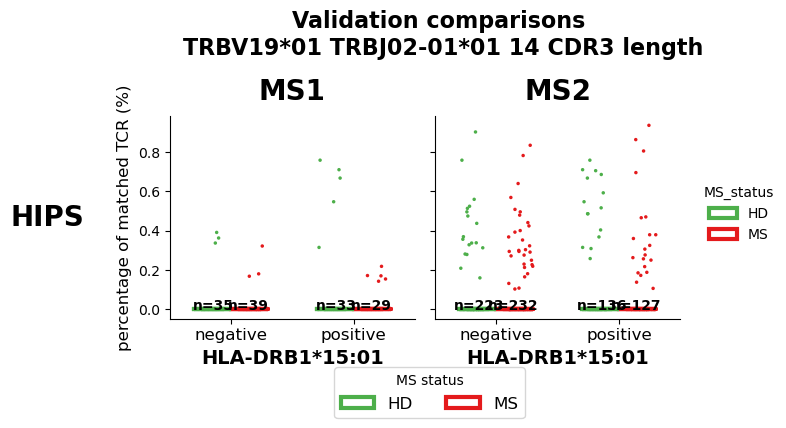

In [48]:
def convert_pvalue_to_asterisks(pvalue):
    if pvalue <= 0.0001:
        return "****"
    elif pvalue <= 0.001:
        return "***"
    elif pvalue <= 0.01:
        return "**"
    elif pvalue <= 0.05:
        return "*"
    return 'ns'

def myfunc(string):
    if 'MS' in string:
        x = 'MS'
    else: x = 'HD'
    return x
    

def annotate(data, **kws):
    
    x = data.groupby(['MS_datasets', 'HD_datasets']).size().index[0]
    p_pos = rslt_df.loc[f'{x}']['p_pos']
    p_hla = rslt_df.loc[f'{x}']['p_hla']
    
    star1 = convert_pvalue_to_asterisks(p_pos)
    star3 = convert_pvalue_to_asterisks(p_hla)

    x1, x2 = 0, 1   # columns 'Sat' and 'Sun' (first column: 0, see plt.xticks())
    x3, x4 = -0.1, 0.1
    x5, x6 = 0.9, 1.1
    y1 = final_df['percentage_vj14'].max()
    y2 = final_df['percentage_vj14'].max() - final_df['percentage_vj14'].max() /0.04
    h = final_df['percentage_vj14'].max()/50
    col = 'black'

    if star3 != 'ns':
        plt.plot([x1, x1, x2, x2], [y1, y1+h, y1+h, y1], lw=1.5, c=col)
        plt.text((x1+x2)*.5, y1, f"{star3}", ha='center', va='bottom', color=col, fontsize=15, fontweight='bold') # {round(p_hla,3)} 
    if star1 != 'ns':
        plt.plot([x5, x5, x6, x6], [y2, y2+h, y2+h, y2], lw=1.5, c=col)
        plt.text((x5+x6)*.5, y2, f"{star1}", ha='center', va='bottom', color=col, fontsize=15, fontweight='bold') # {round(p_pos, 3)} 
    # if star2 != 'ns':
    #     plt.plot([x3, x3, x4, x4], [y2, y2+h, y2+h, y2], lw=1.5, c=col)
    #     plt.text((x3+x4)*.5, y2, f"{star2}", ha='center', va='bottom', color=col, fontsize=15, fontweight='bold') # {round(p_neg, 3)} 
    
    x_labels = ['negative', 'positive']
    x_ticks = [0, 1]
    i=0
    # Print x-tick positions and corresponding labels
    for label, tick in zip(x_labels, x_ticks):
        min_df = data[data['HLA'] == label]

        df1 = min_df[min_df['MS_status'] == 'HD']
        df2 = min_df[min_df['MS_status'] == 'MS']
    
        plt.text(i-0.14, df1['percentage_vj14'].median(), f'n={len(df1)}',ha="center", size=10, fontweight='bold')
        plt.text(i+0.14, df2['percentage_vj14'].median(), f'n={len(df2)}',ha="center", size=10, fontweight='bold')

        i += 1
    plt.xlabel('HLA-DRB1*15:01', fontsize=14, fontweight='bold')
    plt.ylabel('percentage of matched TCR (%)', fontsize=12)

    
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from scipy.stats import wilcoxon, mannwhitneyu
from bioinfokit.analys import stat

ms_datasets = ['ms01', 'ms03']
hd_datasets = ['hips']

final_df = pd.DataFrame()
for ms_dataset in ms_datasets:
    for hd_dataset in hd_datasets:
        subject_df = pd.read_csv(f'./subject_list/{ms_dataset}_hips.tsv', sep='\t')
        subject_list = subject_df.subject_id.values.tolist()

        hla_df1 = pd.read_csv(f'F:/backup_E/meta_data_new_db/{ms_dataset}_hla_typing.tsv', sep='\t')
        hla_df1 = hla_df1[['subject_id', 'HLA_DRB1*15:01']]

        hla_df2 = pd.read_csv(f'F:/backup_E/meta_data_new_db/hips_hla_typing.tsv', sep='\t')
        hla_df2 = hla_df2[['subject_id', 'HLA_DRB1*15:01']]

        hla_df = pd.concat([hla_df1, hla_df2], ignore_index=True, sort=False)
        hla_df.columns=['subject_id', 'HLA']
        
        ms_df = pd.read_csv(f'./comparison_hips/{ms_dataset}_pct_pattern_seqs_length_drss.tsv', sep='\t')
        hd_df = pd.read_csv(f'./comparison_hips/hips_pct_pattern_seqs_length_drss.tsv', sep='\t')
        df = pd.concat([ms_df, hd_df], ignore_index=True, sort=False)
        df['MS_status'] = df.subject_id.apply(lambda x: myfunc(x))
        df = df[df['subject_id'].isin(subject_list)]
        fig_df = df[df['percentage_vj14'] < 0.07]
        fig_df = fig_df.merge(hla_df, on ='subject_id')

        fig_df.insert(0, 'HD_datasets', hd_dataset)
        fig_df.insert(1, 'MS_datasets', ms_dataset)
        final_df = pd.concat([final_df, fig_df], ignore_index=True, sort=False)
        
final_df['MS_status'] = final_df['MS_status'].map({'MS': 1, 'HD': 0})
final_df['percentage_vj14'] = final_df['percentage_vj14']*100
# fig_df = final_df[final_df['percentage_vj16'] < 0.07]
cmap=[sns.color_palette('Set1')[index] for index in [2,0]]

rslt_df = pd.DataFrame()
for dataset, sub_df1 in final_df.groupby(['MS_datasets', 'HD_datasets']):
    sub_df = sub_df1[['percentage_vj14', 'MS_status', 'HLA']]
    # sub_df = sub_df[sub_df['percentage_vj'] > 0]

    hla_pos = sub_df[sub_df['HLA'] == 1]
    hla_neg = sub_df[sub_df['HLA'] == 0]
    stats_hla, p_hla = mannwhitneyu(hla_pos['percentage_vj14'], hla_neg['percentage_vj14'], alternative='greater')

    ms = hla_pos[hla_pos['MS_status'] == 1]
    hd = hla_pos[hla_pos['MS_status'] == 0]
    stats_pos, p_pos = mannwhitneyu(hd['percentage_vj14'], ms['percentage_vj14'], alternative='greater')
    print(dataset, p_pos)
    
    model = ({
        'datasets': [f'{dataset}'],
        'p_pos': [p_pos],
        'p_hla': [p_hla]
    })

    model_df = pd.DataFrame(model)
    rslt_df = pd.concat([rslt_df, model_df], ignore_index=True, sort=False)

rslt_df['datasets'] = rslt_df['datasets'].str.replace('0', '')
rslt_df['datasets'] = rslt_df['datasets'].str.replace('0', '')
rslt_df['datasets'] = rslt_df['datasets'].str.replace('microhd', 'hd3')
rslt_df = rslt_df.set_index('datasets')

final_df["MS_status"] = final_df["MS_status"].map({0: "HD", 1: "MS"})
final_df['HLA'] = final_df['HLA'].map({0: 'negative', 1: 'positive'})
final_df['MS_datasets'] = final_df['MS_datasets'].str.replace('0', '')
final_df['HD_datasets'] = final_df['HD_datasets'].str.replace('0', '')
final_df['HD_datasets'] = final_df['HD_datasets'].str.replace('microhd', 'hd3')

hue_order = ['HD', 'MS']
g = sns.catplot(x="HLA", y="percentage_vj14", hue="MS_status", hue_order=hue_order,
                col='MS_datasets', row='HD_datasets', order=['negative', 'positive'], palette=cmap, legend=True,height=3, aspect=1,
                data=final_df, kind='box', showfliers = False, fill=False, boxprops=dict(linewidth=3), whiskerprops=dict(linewidth=3),
            capprops=dict(linewidth=3), medianprops=dict(linewidth=3), width=0.6)
g.map(sns.stripplot, "HLA", "percentage_vj14", 'MS_status', palette=cmap,
      hue_order=hue_order, jitter=0.2, order=['negative', 'positive'],
      size=2.5, dodge=True, legend=False)
g.map_dataframe(annotate)
# g.set_titles(('{row_name}' ' vs. ' '{col_name}'), size=18, weight='bold')
g.set_titles("")
g.figure.suptitle(
    'Validation comparisons \nTRBV19*01 TRBJ02-01*01 14 CDR3 length',
    fontsize=16,
    fontweight="bold",
    y=1.24
)

for ax, row_name in zip(g.axes[:, 0], g.row_names):
    ax.annotate(row_name.upper(), xy=(-0.5, 0.5), xycoords=ax.transAxes, 
                va='center', ha='center', fontsize=20, weight='bold')

for ax, col_name in zip(g.axes[0], g.col_names):
    if col_name == 'ms3':
        col_name = 'ms2'
    else: col_name = col_name
    ax.set_title(col_name.upper(), fontsize=20, weight='bold', y=1.04)

for ax in g.axes.flat:
    ax.tick_params(axis='x',  labelsize=12)

# g.legend.set_bbox_to_anchor((1.15, 0.5))

plt.legend(bbox_to_anchor=(0.4, -0.2), fontsize=12, ncol=2, title='MS status')

# plt.setp(g.legend.texts, fontsize='16')
# plt.setp(g.legend.get_title(), fontsize='16')

# figre_name = os.path.join('E:/Document/2024/06_18_review_untreated_samples/validation/boxplots/', f'{hla_name}.png')
# plt.savefig(figre_name, bbox_inches='tight')
plt.show()
plt.close()

## pairwise comparisons

('ms01', 'hd01') 0.3603649645461345
('ms01', 'hd02') 0.8138896167757173
('ms01', 'microhd') 0.5054216671607732
('ms03', 'hd01') 0.106948338971744
('ms03', 'hd02') 0.9650533867773541
('ms03', 'microhd') 0.7279408862730774


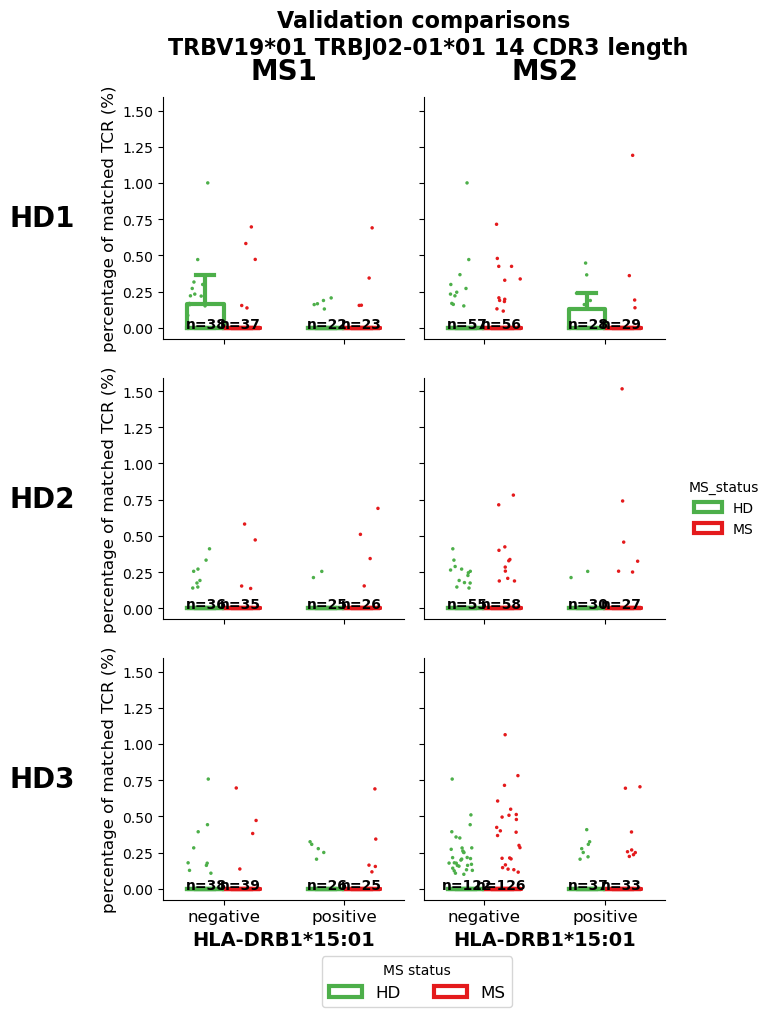

In [70]:
def convert_pvalue_to_asterisks(pvalue):
    if pvalue <= 0.0001:
        return "****"
    elif pvalue <= 0.001:
        return "***"
    elif pvalue <= 0.01:
        return "**"
    elif pvalue <= 0.05:
        return "*"
    return 'ns'

def myfunc(string):
    if 'MS' in string:
        x = 'MS'
    else: x = 'HD'
    return x
    

def annotate(data, **kws):
    
    x = data.groupby(['MS_datasets', 'HD_datasets']).size().index[0]
    p_pos = rslt_df.loc[f'{x}']['p_pos']
    p_hla = rslt_df.loc[f'{x}']['p_hla']
    
    star1 = convert_pvalue_to_asterisks(p_pos)
    star3 = convert_pvalue_to_asterisks(p_hla)

    x1, x2 = 0, 1   # columns 'Sat' and 'Sun' (first column: 0, see plt.xticks())
    x3, x4 = -0.1, 0.1
    x5, x6 = 0.9, 1.1
    y1 = final_df['percentage_vj14'].max()
    y2 = final_df['percentage_vj14'].max() - final_df['percentage_vj14'].max() /0.04
    h = final_df['percentage_vj14'].max()/50
    col = 'black'

    if star3 != 'ns':
        plt.plot([x1, x1, x2, x2], [y1, y1+h, y1+h, y1], lw=1.5, c=col)
        plt.text((x1+x2)*.5, y1, f"{star3}", ha='center', va='bottom', color=col, fontsize=15, fontweight='bold') # {round(p_hla,3)} 
    if star1 != 'ns':
        plt.plot([x5, x5, x6, x6], [y2, y2+h, y2+h, y2], lw=1.5, c=col)
        plt.text((x5+x6)*.5, y2, f"{star1}", ha='center', va='bottom', color=col, fontsize=15, fontweight='bold') # {round(p_pos, 3)} 
    # if star2 != 'ns':
    #     plt.plot([x3, x3, x4, x4], [y2, y2+h, y2+h, y2], lw=1.5, c=col)
    #     plt.text((x3+x4)*.5, y2, f"{star2}", ha='center', va='bottom', color=col, fontsize=15, fontweight='bold') # {round(p_neg, 3)} 
    
    x_labels = ['negative', 'positive']
    x_ticks = [0, 1]
    i=0
    # Print x-tick positions and corresponding labels
    for label, tick in zip(x_labels, x_ticks):
        min_df = data[data['HLA'] == label]

        df1 = min_df[min_df['MS_status'] == 'HD']
        df2 = min_df[min_df['MS_status'] == 'MS']
    
        plt.text(i-0.14, df1['percentage_vj14'].median(), f'n={len(df1)}',ha="center", size=10, fontweight='bold')
        plt.text(i+0.14, df2['percentage_vj14'].median(), f'n={len(df2)}',ha="center", size=10, fontweight='bold')

        i += 1
    plt.xlabel('HLA-DRB1*15:01', fontsize=14, fontweight='bold')
    plt.ylabel('percentage of matched TCR (%)', fontsize=12)

    
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from scipy.stats import wilcoxon, mannwhitneyu
from bioinfokit.analys import stat

ms_datasets = ['ms01', 'ms03']
hd_datasets = ['hd01', 'hd02', 'microhd']

final_df = pd.DataFrame()
for ms_dataset in ms_datasets:
    for hd_dataset in hd_datasets:
        subject_df = pd.read_csv(f'F:/backup_E/2026/subject_list/{ms_dataset}_{hd_dataset}.tsv', sep='\t')
        subject_list = subject_df.subject_id.values.tolist()

        hla_df1 = pd.read_csv(f'F:/backup_E/meta_data_new_db/{ms_dataset}_hla_typing.tsv', sep='\t')
        hla_df1 = hla_df1[['subject_id', 'HLA_DRB1*15:01']]

        hla_df2 = pd.read_csv(f'F:/backup_E/meta_data_new_db/{hd_dataset}_hla_typing.tsv', sep='\t')
        hla_df2 = hla_df2[['subject_id', 'HLA_DRB1*15:01']]

        hla_df = pd.concat([hla_df1, hla_df2], ignore_index=True, sort=False)
        hla_df.columns=['subject_id', 'HLA']
        
        ms_df = pd.read_csv(f'./pairwise_comparison/{ms_dataset}_pct_pattern_seqs.tsv', sep='\t')
        hd_df = pd.read_csv(f'./pairwise_comparison/{hd_dataset}_pct_pattern_seqs.tsv', sep='\t')
        df = pd.concat([ms_df, hd_df], ignore_index=True, sort=False)
        df['MS_status'] = df.subject_id.apply(lambda x: myfunc(x))
        df = df[df['subject_id'].isin(subject_list)]
        fig_df = df[df['percentage_vj14'] < 0.07]
        fig_df = fig_df.merge(hla_df, on ='subject_id')

        fig_df.insert(0, 'HD_datasets', hd_dataset)
        fig_df.insert(1, 'MS_datasets', ms_dataset)
        final_df = pd.concat([final_df, fig_df], ignore_index=True, sort=False)
        
final_df['MS_status'] = final_df['MS_status'].map({'MS': 1, 'HD': 0})
final_df['percentage_vj14'] = final_df['percentage_vj14']*100
# fig_df = final_df[final_df['percentage_vj16'] < 0.07]
cmap=[sns.color_palette('Set1')[index] for index in [2,0]]

rslt_df = pd.DataFrame()
for dataset, sub_df1 in final_df.groupby(['MS_datasets', 'HD_datasets']):
    sub_df = sub_df1[['percentage_vj14', 'MS_status', 'HLA']]
    # sub_df = sub_df[sub_df['percentage_vj'] > 0]

    hla_pos = sub_df[sub_df['HLA'] == 1]
    hla_neg = sub_df[sub_df['HLA'] == 0]
    stats_hla, p_hla = mannwhitneyu(hla_pos['percentage_vj14'], hla_neg['percentage_vj14'], alternative='greater')

    ms = hla_pos[hla_pos['MS_status'] == 1]
    hd = hla_pos[hla_pos['MS_status'] == 0]
    stats_pos, p_pos = mannwhitneyu(hd['percentage_vj14'], ms['percentage_vj14'], alternative='greater')
    print(dataset, p_pos)
    
    model = ({
        'datasets': [f'{dataset}'],
        'p_pos': [p_pos],
        'p_hla': [p_hla]
    })

    model_df = pd.DataFrame(model)
    rslt_df = pd.concat([rslt_df, model_df], ignore_index=True, sort=False)

rslt_df['datasets'] = rslt_df['datasets'].str.replace('0', '')
rslt_df['datasets'] = rslt_df['datasets'].str.replace('0', '')
rslt_df['datasets'] = rslt_df['datasets'].str.replace('microhd', 'hd3')
rslt_df = rslt_df.set_index('datasets')

final_df["MS_status"] = final_df["MS_status"].map({0: "HD", 1: "MS"})
final_df['HLA'] = final_df['HLA'].map({0: 'negative', 1: 'positive'})
final_df['MS_datasets'] = final_df['MS_datasets'].str.replace('0', '')
final_df['HD_datasets'] = final_df['HD_datasets'].str.replace('0', '')
final_df['HD_datasets'] = final_df['HD_datasets'].str.replace('microhd', 'hd3')

hue_order = ['HD', 'MS']
g = sns.catplot(x="HLA", y="percentage_vj14", hue="MS_status", hue_order=hue_order,
                col='MS_datasets', row='HD_datasets', order=['negative', 'positive'], palette=cmap, legend=True,height=3, aspect=1,
                data=final_df, kind='box', showfliers = False, fill=False, boxprops=dict(linewidth=3), whiskerprops=dict(linewidth=3),
            capprops=dict(linewidth=3), medianprops=dict(linewidth=3), width=0.6)
g.map(sns.stripplot, "HLA", "percentage_vj14", 'MS_status', palette=cmap,
      hue_order=hue_order, jitter=0.2, order=['negative', 'positive'],
      size=2.5, dodge=True, legend=False)
g.map_dataframe(annotate)
# g.set_titles(('{row_name}' ' vs. ' '{col_name}'), size=18, weight='bold')
g.set_titles("")
g.figure.suptitle(
    'Validation comparisons \nTRBV19*01 TRBJ02-01*01 14 CDR3 length',
    fontsize=16,
    fontweight="bold",
    y=1.06
)

for ax, row_name in zip(g.axes[:, 0], g.row_names):
    ax.annotate(row_name.upper(), xy=(-0.5, 0.5), xycoords=ax.transAxes, 
                va='center', ha='center', fontsize=20, weight='bold')

for ax, col_name in zip(g.axes[0], g.col_names):
    if col_name == 'ms3':
        col_name = 'ms2'
    else: col_name = col_name
    ax.set_title(col_name.upper(), fontsize=20, weight='bold', y=1.04)

for ax in g.axes.flat:
    ax.tick_params(axis='x',  labelsize=12)

# g.legend.set_bbox_to_anchor((1.15, 0.5))

plt.legend(bbox_to_anchor=(0.4, -0.2), fontsize=12, ncol=2, title='MS status')

# plt.setp(g.legend.texts, fontsize='16')
# plt.setp(g.legend.get_title(), fontsize='16')

# figre_name = os.path.join('E:/Document/2024/06_18_review_untreated_samples/validation/boxplots/', f'{hla_name}.png')
# plt.savefig(figre_name, bbox_inches='tight')
plt.show()
plt.close()

('ms01', 'hd01') 0.026092764133569153
('ms01', 'hd02') 0.019536807591864526
('ms01', 'microhd') 0.0012465496848493077
('ms03', 'hd01') 0.6253428293950601
('ms03', 'hd02') 0.0680692333550322
('ms03', 'microhd') 0.17327360540131864


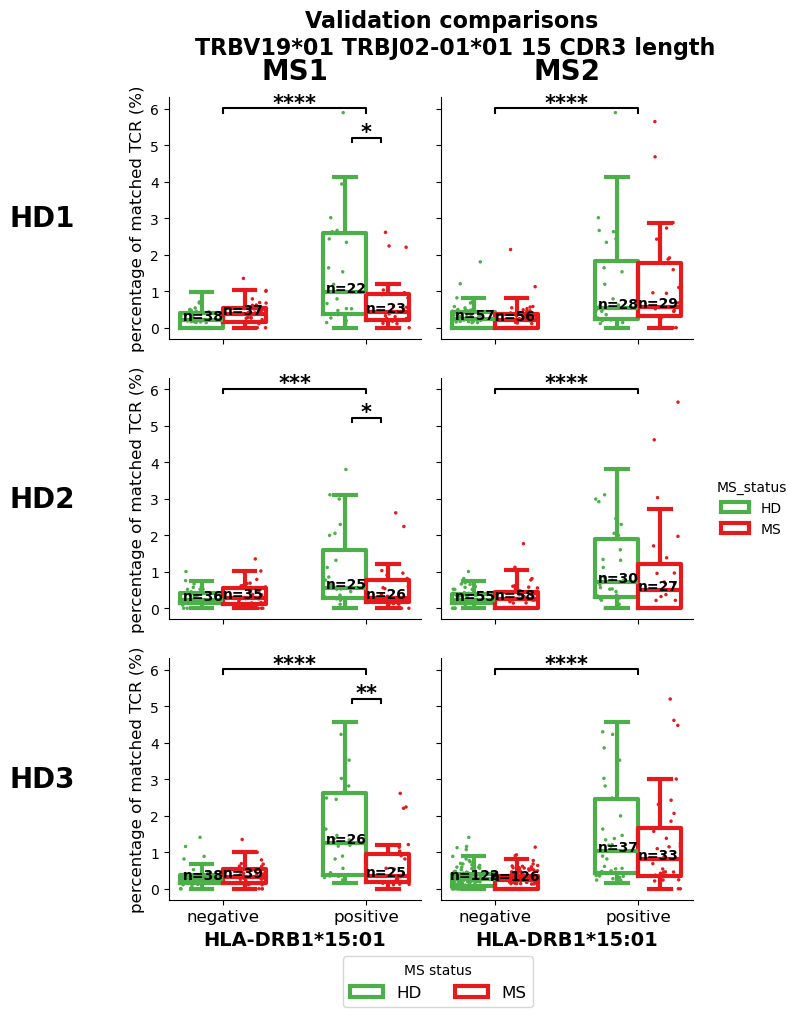

In [2]:
def convert_pvalue_to_asterisks(pvalue):
    if pvalue <= 0.0001:
        return "****"
    elif pvalue <= 0.001:
        return "***"
    elif pvalue <= 0.01:
        return "**"
    elif pvalue <= 0.05:
        return "*"
    return 'ns'

def myfunc(string):
    if 'MS' in string:
        x = 'MS'
    else: x = 'HD'
    return x
    

def annotate(data, **kws):
    
    x = data.groupby(['MS_datasets', 'HD_datasets']).size().index[0]
    p_pos = rslt_df.loc[f'{x}']['p_pos']
    p_hla = rslt_df.loc[f'{x}']['p_hla']
    
    star1 = convert_pvalue_to_asterisks(p_pos)
    star3 = convert_pvalue_to_asterisks(p_hla)

    x1, x2 = 0, 1   # columns 'Sat' and 'Sun' (first column: 0, see plt.xticks())
    x3, x4 = -0.1, 0.1
    x5, x6 = 0.9, 1.1
    y1 = final_df['percentage_vj15'].max()
    y2 = final_df['percentage_vj15'].max() - 0.8
    h = final_df['percentage_vj15'].max()/50
    col = 'black'

    if star3 != 'ns':
        plt.plot([x1, x1, x2, x2], [y1, y1+h, y1+h, y1], lw=1.5, c=col)
        plt.text((x1+x2)*.5, y1, f"{star3}", ha='center', va='bottom', color=col, fontsize=15, fontweight='bold') # {round(p_hla,3)} 
    if star1 != 'ns':
        plt.plot([x5, x5, x6, x6], [y2, y2+h, y2+h, y2], lw=1.5, c=col)
        plt.text((x5+x6)*.5, y2, f"{star1}", ha='center', va='bottom', color=col, fontsize=15, fontweight='bold') # {round(p_pos, 3)} 
    # if star2 != 'ns':
    #     plt.plot([x3, x3, x4, x4], [y2, y2+h, y2+h, y2], lw=1.5, c=col)
    #     plt.text((x3+x4)*.5, y2, f"{star2}", ha='center', va='bottom', color=col, fontsize=15, fontweight='bold') # {round(p_neg, 3)} 
    
    x_labels = ['negative', 'positive']
    x_ticks = [0, 1]
    i=0
    # Print x-tick positions and corresponding labels
    for label, tick in zip(x_labels, x_ticks):
        min_df = data[data['HLA'] == label]

        df1 = min_df[min_df['MS_status'] == 'HD']
        df2 = min_df[min_df['MS_status'] == 'MS']
    
        plt.text(i-0.14, df1['percentage_vj15'].median(), f'n={len(df1)}',ha="center", size=10, fontweight='bold')
        plt.text(i+0.14, df2['percentage_vj15'].median(), f'n={len(df2)}',ha="center", size=10, fontweight='bold')

        i += 1
    plt.xlabel('HLA-DRB1*15:01', fontsize=14, fontweight='bold')
    plt.ylabel('percentage of matched TCR (%)', fontsize=12)

    
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from scipy.stats import wilcoxon, mannwhitneyu
from bioinfokit.analys import stat

ms_datasets = ['ms01', 'ms03']
hd_datasets = ['hd01', 'hd02', 'microhd']

final_df = pd.DataFrame()
for ms_dataset in ms_datasets:
    for hd_dataset in hd_datasets:
        subject_df = pd.read_csv(f'F:/backup_E/2026/subject_list/{ms_dataset}_{hd_dataset}.tsv', sep='\t')
        subject_list = subject_df.subject_id.values.tolist()

        hla_df1 = pd.read_csv(f'F:/backup_E/meta_data_new_db/{ms_dataset}_hla_typing.tsv', sep='\t')
        hla_df1 = hla_df1[['subject_id', 'HLA_DRB1*15:01']]

        hla_df2 = pd.read_csv(f'F:/backup_E/meta_data_new_db/{hd_dataset}_hla_typing.tsv', sep='\t')
        hla_df2 = hla_df2[['subject_id', 'HLA_DRB1*15:01']]

        hla_df = pd.concat([hla_df1, hla_df2], ignore_index=True, sort=False)
        hla_df.columns=['subject_id', 'HLA']
        
        ms_df = pd.read_csv(f'./pairwise_comparison/{ms_dataset}_pct_pattern_seqs.tsv', sep='\t')
        hd_df = pd.read_csv(f'./pairwise_comparison/{hd_dataset}_pct_pattern_seqs.tsv', sep='\t')
        df = pd.concat([ms_df, hd_df], ignore_index=True, sort=False)
        df['MS_status'] = df.subject_id.apply(lambda x: myfunc(x))
        df = df[df['subject_id'].isin(subject_list)]
        fig_df = df[df['percentage_vj15'] < 0.07]
        fig_df = fig_df.merge(hla_df, on ='subject_id')

        fig_df.insert(0, 'HD_datasets', hd_dataset)
        fig_df.insert(1, 'MS_datasets', ms_dataset)
        final_df = pd.concat([final_df, fig_df], ignore_index=True, sort=False)
        
final_df['MS_status'] = final_df['MS_status'].map({'MS': 1, 'HD': 0})
final_df['percentage_vj15'] = final_df['percentage_vj15']*100
# fig_df = final_df[final_df['percentage_vj16'] < 0.07]
cmap=[sns.color_palette('Set1')[index] for index in [2,0]]

rslt_df = pd.DataFrame()
for dataset, sub_df1 in final_df.groupby(['MS_datasets', 'HD_datasets']):
    sub_df = sub_df1[['percentage_vj15', 'MS_status', 'HLA']]
    # sub_df = sub_df[sub_df['percentage_vj'] > 0]

    hla_pos = sub_df[sub_df['HLA'] == 1]
    hla_neg = sub_df[sub_df['HLA'] == 0]
    stats_hla, p_hla = mannwhitneyu(hla_pos['percentage_vj15'], hla_neg['percentage_vj15'], alternative='greater')

    ms = hla_pos[hla_pos['MS_status'] == 1]
    hd = hla_pos[hla_pos['MS_status'] == 0]
    stats_pos, p_pos = mannwhitneyu(hd['percentage_vj15'], ms['percentage_vj15'], alternative='greater')
    print(dataset, p_pos)
    
    model = ({
        'datasets': [f'{dataset}'],
        'p_pos': [p_pos],
        'p_hla': [p_hla]
    })

    model_df = pd.DataFrame(model)
    rslt_df = pd.concat([rslt_df, model_df], ignore_index=True, sort=False)

rslt_df['datasets'] = rslt_df['datasets'].str.replace('0', '')
rslt_df['datasets'] = rslt_df['datasets'].str.replace('0', '')
rslt_df['datasets'] = rslt_df['datasets'].str.replace('microhd', 'hd3')
rslt_df = rslt_df.set_index('datasets')

final_df["MS_status"] = final_df["MS_status"].map({0: "HD", 1: "MS"})
final_df['HLA'] = final_df['HLA'].map({0: 'negative', 1: 'positive'})
final_df['MS_datasets'] = final_df['MS_datasets'].str.replace('0', '')
final_df['HD_datasets'] = final_df['HD_datasets'].str.replace('0', '')
final_df['HD_datasets'] = final_df['HD_datasets'].str.replace('microhd', 'hd3')

hue_order = ['HD', 'MS']
g = sns.catplot(x="HLA", y="percentage_vj15", hue="MS_status", hue_order=hue_order,
                col='MS_datasets', row='HD_datasets', order=['negative', 'positive'], palette=cmap, legend=True,height=3, aspect=1,
                data=final_df, kind='box', showfliers = False, fill=False, boxprops=dict(linewidth=3), whiskerprops=dict(linewidth=3),
            capprops=dict(linewidth=3), medianprops=dict(linewidth=3), width=0.6)
g.map(sns.stripplot, "HLA", "percentage_vj15", 'MS_status', palette=cmap,
      hue_order=hue_order, jitter=0.2, order=['negative', 'positive'],
      size=2.5, dodge=True, legend=False)
g.map_dataframe(annotate)
# g.set_titles(('{row_name}' ' vs. ' '{col_name}'), size=18, weight='bold')
g.set_titles("")
g.figure.suptitle(
    'Validation comparisons \nTRBV19*01 TRBJ02-01*01 15 CDR3 length',
    fontsize=16,
    fontweight="bold",
    y=1.06
)

for ax, row_name in zip(g.axes[:, 0], g.row_names):
    ax.annotate(row_name.upper(), xy=(-0.5, 0.5), xycoords=ax.transAxes, 
                va='center', ha='center', fontsize=20, weight='bold')

for ax, col_name in zip(g.axes[0], g.col_names):
    if col_name == 'ms3':
        col_name = 'ms2'
    else: col_name = col_name
    ax.set_title(col_name.upper(), fontsize=20, weight='bold', y=1.04)

for ax in g.axes.flat:
    ax.tick_params(axis='x',  labelsize=12)

# g.legend.set_bbox_to_anchor((1.15, 0.5))

plt.legend(bbox_to_anchor=(0.4, -0.2), fontsize=12, ncol=2, title='MS status')

# plt.setp(g.legend.texts, fontsize='16')
# plt.setp(g.legend.get_title(), fontsize='16')

# figre_name = os.path.join('E:/Document/2024/06_18_review_untreated_samples/validation/boxplots/', f'{hla_name}.png')
# plt.savefig(figre_name, bbox_inches='tight')
plt.show()
plt.close()

In [3]:
g.savefig('C:/Users/lynda/Desktop/Figures/Fig5/revised_D.png', format='png', dpi=600, bbox_inches='tight')

('ms01', 'hd01') 0.008112960241878964
('ms01', 'hd02') 0.21997585957682142
('ms01', 'microhd') 0.0493978226542895
('ms03', 'hd01') 0.2651617734568964
('ms03', 'hd02') 0.4465481348792409
('ms03', 'microhd') 0.03497083140011914


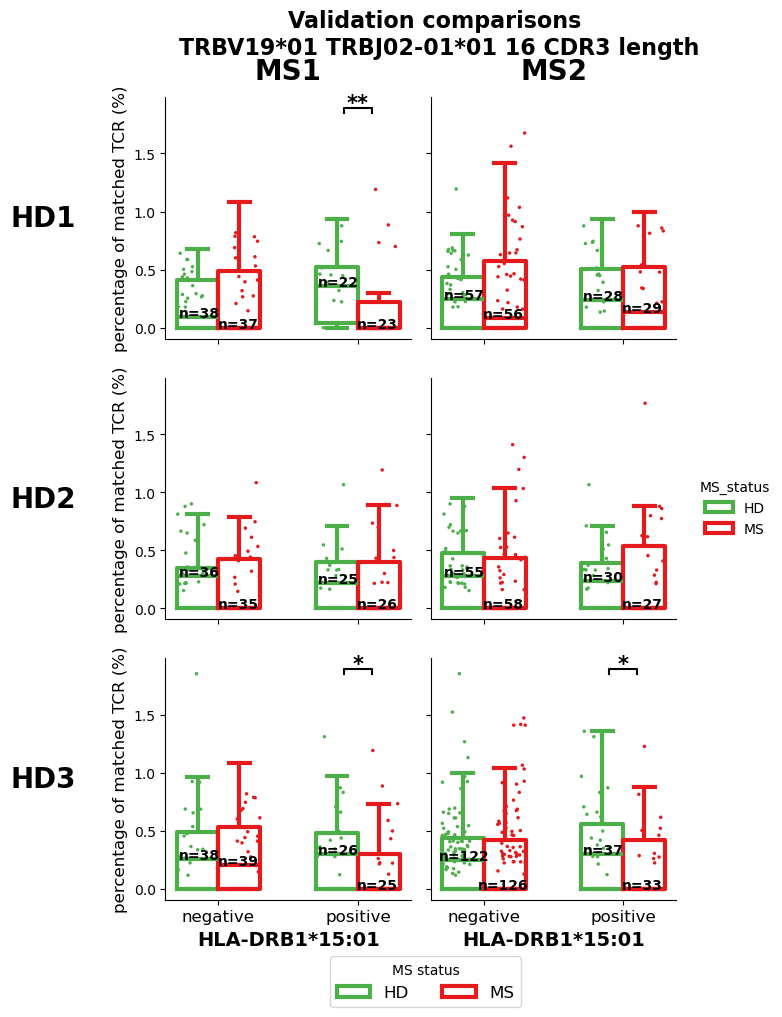

In [76]:
def convert_pvalue_to_asterisks(pvalue):
    if pvalue <= 0.0001:
        return "****"
    elif pvalue <= 0.001:
        return "***"
    elif pvalue <= 0.01:
        return "**"
    elif pvalue <= 0.05:
        return "*"
    return 'ns'

def myfunc(string):
    if 'MS' in string:
        x = 'MS'
    else: x = 'HD'
    return x
    

def annotate(data, **kws):
    
    x = data.groupby(['MS_datasets', 'HD_datasets']).size().index[0]
    p_pos = rslt_df.loc[f'{x}']['p_pos']
    p_hla = rslt_df.loc[f'{x}']['p_hla']
    
    star1 = convert_pvalue_to_asterisks(p_pos)
    star3 = convert_pvalue_to_asterisks(p_hla)

    x1, x2 = 0, 1   # columns 'Sat' and 'Sun' (first column: 0, see plt.xticks())
    x3, x4 = -0.1, 0.1
    x5, x6 = 0.9, 1.1
    y1 = final_df['percentage_vj16'].max()
    y2 = final_df['percentage_vj16'].max() #- final_df['percentage_vj16'].max() /0.04
    h = final_df['percentage_vj16'].max()/50
    col = 'black'

    if star3 != 'ns':
        plt.plot([x1, x1, x2, x2], [y1, y1+h, y1+h, y1], lw=1.5, c=col)
        plt.text((x1+x2)*.5, y1, f"{star3}", ha='center', va='bottom', color=col, fontsize=15, fontweight='bold') # {round(p_hla,3)} 
    if star1 != 'ns':
        plt.plot([x5, x5, x6, x6], [y2, y2+h, y2+h, y2], lw=1.5, c=col)
        plt.text((x5+x6)*.5, y2, f"{star1}", ha='center', va='bottom', color=col, fontsize=15, fontweight='bold') # {round(p_pos, 3)} 
    # if star2 != 'ns':
    #     plt.plot([x3, x3, x4, x4], [y2, y2+h, y2+h, y2], lw=1.5, c=col)
    #     plt.text((x3+x4)*.5, y2, f"{star2}", ha='center', va='bottom', color=col, fontsize=15, fontweight='bold') # {round(p_neg, 3)} 
    
    x_labels = ['negative', 'positive']
    x_ticks = [0, 1]
    i=0
    # Print x-tick positions and corresponding labels
    for label, tick in zip(x_labels, x_ticks):
        min_df = data[data['HLA'] == label]

        df1 = min_df[min_df['MS_status'] == 'HD']
        df2 = min_df[min_df['MS_status'] == 'MS']
    
        plt.text(i-0.14, df1['percentage_vj16'].median(), f'n={len(df1)}',ha="center", size=10, fontweight='bold')
        plt.text(i+0.14, df2['percentage_vj16'].median(), f'n={len(df2)}',ha="center", size=10, fontweight='bold')

        i += 1
    plt.xlabel('HLA-DRB1*15:01', fontsize=14, fontweight='bold')
    plt.ylabel('percentage of matched TCR (%)', fontsize=12)

    
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

from scipy.stats import wilcoxon, mannwhitneyu
from bioinfokit.analys import stat

ms_datasets = ['ms01', 'ms03']
hd_datasets = ['hd01', 'hd02', 'microhd']

final_df = pd.DataFrame()
for ms_dataset in ms_datasets:
    for hd_dataset in hd_datasets:
        subject_df = pd.read_csv(f'F:/backup_E/2026/subject_list/{ms_dataset}_{hd_dataset}.tsv', sep='\t')
        subject_list = subject_df.subject_id.values.tolist()

        hla_df1 = pd.read_csv(f'F:/backup_E/meta_data_new_db/{ms_dataset}_hla_typing.tsv', sep='\t')
        hla_df1 = hla_df1[['subject_id', 'HLA_DRB1*15:01']]

        hla_df2 = pd.read_csv(f'F:/backup_E/meta_data_new_db/{hd_dataset}_hla_typing.tsv', sep='\t')
        hla_df2 = hla_df2[['subject_id', 'HLA_DRB1*15:01']]

        hla_df = pd.concat([hla_df1, hla_df2], ignore_index=True, sort=False)
        hla_df.columns=['subject_id', 'HLA']
        
        ms_df = pd.read_csv(f'./pairwise_comparison/{ms_dataset}_pct_pattern_seqs.tsv', sep='\t')
        hd_df = pd.read_csv(f'./pairwise_comparison/{hd_dataset}_pct_pattern_seqs.tsv', sep='\t')
        df = pd.concat([ms_df, hd_df], ignore_index=True, sort=False)
        df['MS_status'] = df.subject_id.apply(lambda x: myfunc(x))
        df = df[df['subject_id'].isin(subject_list)]
        fig_df = df.copy() #df[df['percentage_vj16'] < 0.07]
        fig_df = fig_df.merge(hla_df, on ='subject_id')

        fig_df.insert(0, 'HD_datasets', hd_dataset)
        fig_df.insert(1, 'MS_datasets', ms_dataset)
        final_df = pd.concat([final_df, fig_df], ignore_index=True, sort=False)
        
final_df['MS_status'] = final_df['MS_status'].map({'MS': 1, 'HD': 0})
final_df['percentage_vj16'] = final_df['percentage_vj16']*100
# fig_df = final_df[final_df['percentage_vj16'] < 0.07]
cmap=[sns.color_palette('Set1')[index] for index in [2,0]]

rslt_df = pd.DataFrame()
for dataset, sub_df1 in final_df.groupby(['MS_datasets', 'HD_datasets']):
    sub_df = sub_df1[['percentage_vj16', 'MS_status', 'HLA']]
    # sub_df = sub_df[sub_df['percentage_vj'] > 0]

    hla_pos = sub_df[sub_df['HLA'] == 1]
    hla_neg = sub_df[sub_df['HLA'] == 0]
    stats_hla, p_hla = mannwhitneyu(hla_pos['percentage_vj16'], hla_neg['percentage_vj16'], alternative='greater')

    ms = hla_pos[hla_pos['MS_status'] == 1]
    hd = hla_pos[hla_pos['MS_status'] == 0]
    stats_pos, p_pos = mannwhitneyu(hd['percentage_vj16'], ms['percentage_vj16'], alternative='greater')
    print(dataset, p_pos)
    
    model = ({
        'datasets': [f'{dataset}'],
        'p_pos': [p_pos],
        'p_hla': [p_hla]
    })

    model_df = pd.DataFrame(model)
    rslt_df = pd.concat([rslt_df, model_df], ignore_index=True, sort=False)

rslt_df['datasets'] = rslt_df['datasets'].str.replace('0', '')
rslt_df['datasets'] = rslt_df['datasets'].str.replace('0', '')
rslt_df['datasets'] = rslt_df['datasets'].str.replace('microhd', 'hd3')
rslt_df = rslt_df.set_index('datasets')

final_df["MS_status"] = final_df["MS_status"].map({0: "HD", 1: "MS"})
final_df['HLA'] = final_df['HLA'].map({0: 'negative', 1: 'positive'})
final_df['MS_datasets'] = final_df['MS_datasets'].str.replace('0', '')
final_df['HD_datasets'] = final_df['HD_datasets'].str.replace('0', '')
final_df['HD_datasets'] = final_df['HD_datasets'].str.replace('microhd', 'hd3')

hue_order = ['HD', 'MS']
g = sns.catplot(x="HLA", y="percentage_vj16", hue="MS_status", hue_order=hue_order,
                col='MS_datasets', row='HD_datasets', order=['negative', 'positive'], palette=cmap, legend=True,height=3, aspect=1,
                data=final_df, kind='box', showfliers = False, fill=False, boxprops=dict(linewidth=3), whiskerprops=dict(linewidth=3),
            capprops=dict(linewidth=3), medianprops=dict(linewidth=3), width=0.6)
g.map(sns.stripplot, "HLA", "percentage_vj16", 'MS_status', palette=cmap,
      hue_order=hue_order, jitter=0.2, order=['negative', 'positive'],
      size=2.5, dodge=True, legend=False)
g.map_dataframe(annotate)
# g.set_titles(('{row_name}' ' vs. ' '{col_name}'), size=18, weight='bold')
g.set_titles("")
g.figure.suptitle(
    'Validation comparisons \nTRBV19*01 TRBJ02-01*01 16 CDR3 length',
    fontsize=16,
    fontweight="bold",
    y=1.06
)

for ax, row_name in zip(g.axes[:, 0], g.row_names):
    ax.annotate(row_name.upper(), xy=(-0.5, 0.5), xycoords=ax.transAxes, 
                va='center', ha='center', fontsize=20, weight='bold')

for ax, col_name in zip(g.axes[0], g.col_names):
    if col_name == 'ms3':
        col_name = 'ms2'
    else: col_name = col_name
    ax.set_title(col_name.upper(), fontsize=20, weight='bold', y=1.04)

for ax in g.axes.flat:
    ax.tick_params(axis='x',  labelsize=12)

# g.legend.set_bbox_to_anchor((1.15, 0.5))

plt.legend(bbox_to_anchor=(0.4, -0.2), fontsize=12, ncol=2, title='MS status')

# plt.setp(g.legend.texts, fontsize='16')
# plt.setp(g.legend.get_title(), fontsize='16')

# figre_name = os.path.join('E:/Document/2024/06_18_review_untreated_samples/validation/boxplots/', f'{hla_name}.png')
# plt.savefig(figre_name, bbox_inches='tight')
plt.show()
plt.close()